# ETH/USDT 日频动态网格回测

基于 **vnpy 4.4.0** 的 `vnpy.alpha` 回测框架，对 ETH/USDT 日线做**动态网格交易法**回测。

- 数据来源：Binance，日频 K 线缓存于 `data/eth_usdt_1d.csv`
- 网格为固定价格区间 `[GRID_LOWER, GRID_UPPER]`，**价格超出上下界时暂停交易**
- **动态挂单**：以当前价格向下最接近的网格价 $P_t$ 为锚，在上方网格按网格价挂卖单、在下方网格按网格价挂买单；
  当价格突破 $N$ 个网格（$N$ 为观测结果，即当日相对前日价格跨越的网格数）成交后，在原成交网格价处**追加**反手挂单
- 暂不考虑复杂风控（无止损、无动态仓位管理）

所有可调参数集中在「参数设置」单元格，修改后从头重跑即可。


In [1]:
# ---- vnpy.alpha 可选依赖兼容处理 ----
# vnpy.alpha 包顶层会导入 alphalens / talib / torch / lightgbm 等可选依赖。
# 本项目仅使用其中的回测引擎 (BacktestingEngine) 与数据实验室 (AlphaLab)，
# 对未安装的可选依赖注入空实现，避免导入失败。
import sys
import types

_STUB_ATTRS = {
    "alphalens": {},
    "alphalens.utils": {"get_clean_factor_and_forward_returns": lambda *a, **k: None},
    "alphalens.tears": {"create_full_tear_sheet": lambda *a, **k: None},
    "talib": {},
    "torch": {},
    "torch.nn": {},
    "torch.optim": {},
    "lightgbm": {},
}
for _name, _attrs in _STUB_ATTRS.items():
    if _name in sys.modules:
        continue
    _mod = types.ModuleType(_name)
    for _k, _v in _attrs.items():
        setattr(_mod, _k, _v)
    sys.modules[_name] = _mod

# ---- 常用库 ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from vnpy.alpha import AlphaLab, AlphaStrategy, BacktestingEngine
from vnpy.trader.object import BarData
from vnpy.trader.constant import Direction, Exchange, Interval

## 参数设置

In [2]:
# ================= 统一可调参数 =================

# --- 数据与回测区间 ---
DATA_PATH = "../data/eth_usdt_1d.csv"     # 日线数据路径（相对 notebook 目录）
START = "2021-05-01"                       # 回测起始日期（震荡行情区间）
END = "2021-10-31"                         # 回测结束日期

# --- 网格参数（手动填写网格上下界） ---
GRID_LOWER = 1800                          # 网格下界 (USDT)，价格低于此暂停交易
GRID_UPPER = 3600                          # 网格上界 (USDT)，价格高于此暂停交易
GRID_STEPS = 50                            # 网格层数（上下界之间切分档数）
VOLUME_PER_GRID = 1.0                      # 每格成交数量 (ETH)
INITIAL_BASE_RATIO = 0.5                   # 初始底仓占资金比例 (0~1)

# --- 资金 / 费率 / vnpy ---
INIT_CAPITAL = 100_000                     # 初始资金 (USDT)
FEE_RATE = 0.001                           # 单边手续费率（币安现货 0.1%）
PRICE_TICK = 0.01                          # 最小价格变动
VT_SYMBOL = "ETHUSDT.GLOBAL"               # vnpy 合约代码（枚举无 BINANCE，用 GLOBAL 兜底）
LAB_PATH = "../data/vnpy_lab"              # vnpy 数据实验室目录（存放 parquet 与合约配置）

GRID_STEP_PRICE = (GRID_UPPER - GRID_LOWER) / GRID_STEPS
print(f"网格价格间距: {GRID_STEP_PRICE:.2f} USDT")

网格价格间距: 36.00 USDT


## 统计数据与网格参数分析

先对回测区间内的价格做统计，为网格参数（区间 / 层数 / 每格数量）提供参考依据。


In [3]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df["pct_change"] = df["close"].pct_change()
df["daily_range"] = (df["high"] - df["low"]) / df["close"]

in_range = (df["timestamp"] >= START) & (df["timestamp"] <= END)
bdf = df[in_range].reset_index(drop=True)

print(f"全部数据行数: {len(df)}，回测区间行数: {len(bdf)}")
print(f"区间: {bdf['timestamp'].min().date()} ~ {bdf['timestamp'].max().date()}")

print("\n===== 收盘价描述统计 (USDT) =====")
print(bdf["close"].describe(percentiles=[.01, .05, .1, .25, .5, .75, .9, .95, .99]).to_string())
print(f"\n历史最高 ATH: {bdf['high'].max():.2f}  |  历史最低 ATL: {bdf['low'].min():.2f}")

全部数据行数: 1826，回测区间行数: 184
区间: 2021-05-01 ~ 2021-10-31

===== 收盘价描述统计 (USDT) =====
count     184.000000
mean     2977.067935
std       683.090308
min      1786.820000
1%       1815.907000
5%       1919.863000
10%      2086.513000
25%      2368.500000
50%      3013.070000
75%      3481.842500
90%      3917.290000
95%      4082.079500
99%      4291.673400
max      4418.940000

历史最高 ATH: 4460.01  |  历史最低 ATL: 1700.51


In [4]:
ret = bdf["close"].pct_change().dropna()
rng = bdf["daily_range"].dropna()
annual_vol = ret.std() * np.sqrt(252) * 100

print("===== 日收益率 (%) =====")
print((ret * 100).describe(percentiles=[.05, .25, .5, .75, .95]).to_string())
print(f"\n年化波动率: {annual_vol:.2f}%")

print("\n===== 日振幅 (high-low)/close (%) =====")
print((rng * 100).describe(percentiles=[.5, .75, .9]).to_string())

def max_run(s):
    m = cur = 0
    for x in s:
        cur = cur + 1 if x > 0 else 0
        m = max(m, cur)
    return m

print(f"\n最大连涨天数: {max_run(np.sign(ret))}，最大连跌天数: {max_run(-np.sign(ret))}")

===== 日收益率 (%) =====
count    183.000000
mean       0.386577
std        6.004256
min      -27.804395
5%        -8.611170
25%       -2.944933
50%        0.435523
75%        3.592576
95%        9.549099
max       26.301328

年化波动率: 95.31%

===== 日振幅 (high-low)/close (%) =====
count    184.000000
mean       8.894237
std        6.468623
min        2.347541
50%        7.232511
75%        9.966432
90%       14.441122
max       63.250950

最大连涨天数: 7，最大连跌天数: 3


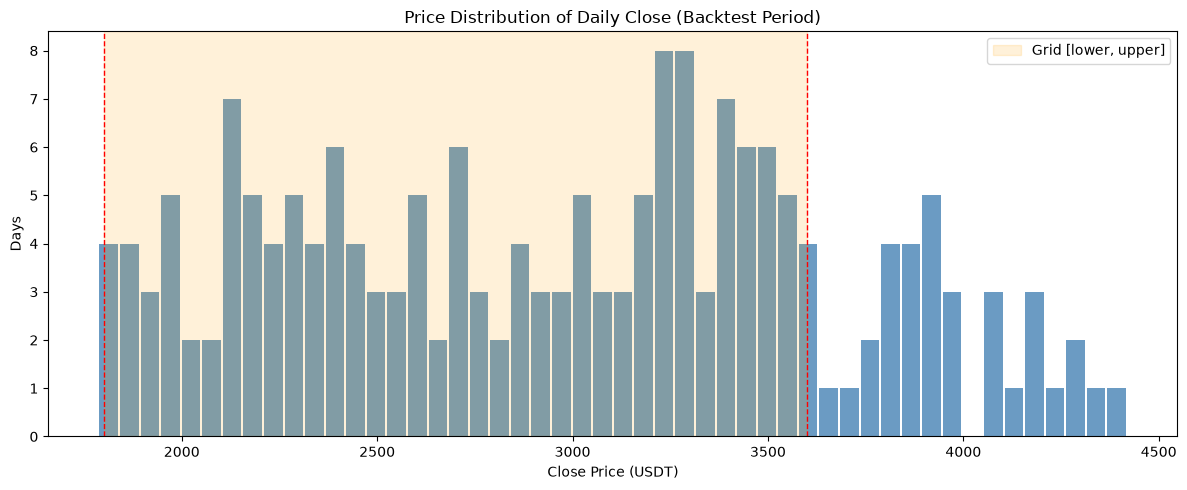

网格区间 [1800, 3600] 内天数: 149 (81.0%)
低于下界天数: 1 (0.5%)  <- 暂停交易
高于上界天数: 34 (18.5%)  <- 暂停交易


In [5]:
# 全期收盘价分 50 档，统计停留天数
n_bins = 50
bins = np.linspace(bdf["close"].min(), bdf["close"].max(), n_bins + 1)
hist, edges = np.histogram(bdf["close"], bins=bins)
centers = (edges[:-1] + edges[1:]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(centers, hist, width=(edges[1] - edges[0]) * 0.9, color="steelblue", alpha=0.8)
ax.axvspan(GRID_LOWER, GRID_UPPER, color="orange", alpha=0.15, label="Grid [lower, upper]")
ax.axvline(GRID_LOWER, color="red", ls="--", lw=1)
ax.axvline(GRID_UPPER, color="red", ls="--", lw=1)
ax.set_xlabel("Close Price (USDT)")
ax.set_ylabel("Days")
ax.set_title("Price Distribution of Daily Close (Backtest Period)")
ax.legend()
plt.tight_layout()
plt.show()

n_total = len(bdf)
n_in = int(((bdf["close"] >= GRID_LOWER) & (bdf["close"] <= GRID_UPPER)).sum())
n_low = int((bdf["close"] < GRID_LOWER).sum())
n_high = int((bdf["close"] > GRID_UPPER).sum())
print(f"网格区间 [{GRID_LOWER}, {GRID_UPPER}] 内天数: {n_in} ({n_in / n_total * 100:.1f}%)")
print(f"低于下界天数: {n_low} ({n_low / n_total * 100:.1f}%)  <- 暂停交易")
print(f"高于上界天数: {n_high} ({n_high / n_total * 100:.1f}%)  <- 暂停交易")


## vnpy 数据准备

将回测区间内的 CSV 数据写入 `AlphaLab`（存为 parquet），并登记合约交易参数（手续费 / 合约乘数 / 最小变动价位）。


In [6]:
lab = AlphaLab(LAB_PATH)
symbol = VT_SYMBOL.split(".")[0]

bars = []
for r in bdf.itertuples():
    bars.append(BarData(
        symbol=symbol,
        exchange=Exchange("GLOBAL"),
        datetime=r.timestamp.to_pydatetime(),
        interval=Interval.DAILY,
        open_price=r.open,
        high_price=r.high,
        low_price=r.low,
        close_price=r.close,
        volume=r.volume,
        gateway_name="DB",
    ))

lab.save_bar_data(bars)
lab.add_contract_setting(
    VT_SYMBOL,
    long_rate=FEE_RATE,
    short_rate=FEE_RATE,
    size=1,
    pricetick=PRICE_TICK,
)
print(f"已写入 {len(bars)} 根日线 -> {LAB_PATH}/daily/{VT_SYMBOL}.parquet")


已写入 184 根日线 -> ../data/vnpy_lab/daily/ETHUSDT.GLOBAL.parquet


## 动态挂单策略定义

策略逻辑（动态网格，每日收盘判断）：

1. **初始底仓**：首个交易日按收盘价买入 `INIT_CAPITAL * INITIAL_BASE_RATIO` 市值的 ETH。
2. **初始挂单簿**：以当日收盘价向下最接近的网格价 $P_t$ 为锚，在上方全部网格按网格价挂**卖单**、
   在下方全部网格按网格价挂**买单**（每格 `VOLUME_PER_GRID`，卖出总量不超过持仓、买入总额不超过可用现金）。
3. **网格翻面（动态挂单）**：$N$ 是**观测值**而非参数——若次日价格向上突破 $N$ 个网格，则原挂在
   那 $N$ 个网格的卖单成交，此时**追加**在恰好这 $N$ 个网格价处挂买单；对称地，价格向下突破 $N$ 个网格时，
   成交的 $N$ 个买单处**追加**挂卖单。追加后该网格“翻面”，带宽随价格滚动。
4. **挂单持久有效**：挂单保留至成交，不每日撤单（让「追加买单」能等待价格回落成交）。
5. **暂停规则**：收盘价超出 `[GRID_LOWER, GRID_UPPER]` 时当日不发任何新单（暂停交易），价格回到区间内恢复。


In [7]:
class DynamicGridStrategy(AlphaStrategy):
    """动态网格策略：以当前价格向下最接近的网格价 Pt 为锚，上方挂卖单、下方挂买单；
    价格突破 N 格（N 为观测值）成交后，在成交网格价处追加反手挂单。
    挂单持久有效直至成交；收盘价超出网格区间时暂停发新单。"""

    def on_init(self) -> None:
        self.volume_per_grid = VOLUME_PER_GRID
        self.step_price = (GRID_UPPER - GRID_LOWER) / GRID_STEPS
        self.grid_prices = [GRID_LOWER + self.step_price * i for i in range(GRID_STEPS + 1)]

        # 持久挂单簿 {网格价: 数量}
        self.standing_sells: dict[float, float] = {}
        self.standing_buys: dict[float, float] = {}
        # orderid(vt_orderid) -> 网格价（成交反查）
        self.order_level: dict[str, float] = {}
        # 追加队列：成交的卖单格 -> 待挂买单；成交的买单格 -> 待挂卖单
        self.roll_to_buy: list[float] = []
        self.roll_to_sell: list[float] = []

        self.base_pos_done: bool = False
        # 初始底仓尚未成交期间，用于挂单簿的资金/持仓占用
        self.pending_base_vol: float = 0.0
        self.pending_base_cost: float = 0.0

    def floor_grid(self, price: float) -> float:
        """当前价格向下最接近的网格价 Pt"""
        idx = int((price - GRID_LOWER) / self.step_price)
        idx = min(max(idx, 0), GRID_STEPS)
        return GRID_LOWER + idx * self.step_price

    def sell_capacity(self) -> float:
        """可卖持仓 = 实际持仓 + 未成交的底仓（首日占用）"""
        pending = self.pending_base_vol if self.pending_base_cost > 0 else 0.0
        return self.get_pos(VT_SYMBOL) + pending

    def buy_cash(self) -> float:
        """可买现金 = 可用现金 - 未成交底仓占用"""
        pending = self.pending_base_cost if self.pending_base_cost > 0 else 0.0
        return self.get_cash_available() - pending

    def place_sell_at(self, price: float, vol: float) -> float:
        """挂卖单（总量不超过可卖持仓），返回实际可挂量"""
        committed = sum(self.standing_sells.values())
        avail = max(0.0, self.sell_capacity() - committed)
        vol = min(vol, avail)
        if vol > 0:
            oids = self.sell(VT_SYMBOL, price, vol)
            self.standing_sells[price] = self.standing_sells.get(price, 0.0) + vol
            for oid in oids:
                self.order_level[oid] = price
        return vol

    def place_buy_at(self, price: float, vol: float) -> float:
        """挂买单（总额不超过可买现金，预留手续费），返回实际可挂量"""
        committed = sum(p * v for p, v in self.standing_buys.items())
        avail_cash = max(0.0, self.buy_cash() - committed)
        vol = min(vol, avail_cash / (price * (1 + FEE_RATE)))
        if vol > 0:
            oids = self.buy(VT_SYMBOL, price, vol)
            self.standing_buys[price] = self.standing_buys.get(price, 0.0) + vol
            for oid in oids:
                self.order_level[oid] = price
        return vol

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return
        close = bar.close_price

        # 首日：买入初始底仓，并以收盘价向下最近网格 Pt 为锚建立初始挂单簿
        if not self.base_pos_done:
            base_vol = min(
                INIT_CAPITAL * INITIAL_BASE_RATIO / close,
                self.get_cash_available() / close,
            )
            if base_vol > 0:
                self.buy(VT_SYMBOL, close, base_vol)
                self.pending_base_vol = base_vol
                self.pending_base_cost = base_vol * close
            self.base_pos_done = True

            anchor = self.floor_grid(close)
            for p in self.grid_prices:
                if p > anchor:
                    self.place_sell_at(p, self.volume_per_grid)
            for p in self.grid_prices:
                if p < anchor:
                    self.place_buy_at(p, self.volume_per_grid)
            return

        # 收盘价超出网格区间 -> 暂停发新单（原挂单保留，成交后不再追加）
        if not (GRID_LOWER <= close <= GRID_UPPER):
            return

        # 追加：卖单成交格 -> 挂买单；买单成交格 -> 挂卖单
        for p in self.roll_to_buy:
            self.place_buy_at(p, self.volume_per_grid)
        self.roll_to_buy.clear()
        for p in self.roll_to_sell:
            self.place_sell_at(p, self.volume_per_grid)
        self.roll_to_sell.clear()

    def on_trade(self, trade) -> None:
        self.write_log(f"成交 {trade.direction.value} {trade.volume:.4f} @ {trade.price:.2f}")

        level = self.order_level.pop(trade.vt_orderid, None)
        if level is None:
            # 初始底仓成交：释放挂单簿占用，不参与翻面
            self.pending_base_vol = 0.0
            self.pending_base_cost = 0.0
            return

        if trade.direction == Direction.LONG:
            self.standing_buys[level] -= trade.volume
            if self.standing_buys[level] <= 1e-9:
                del self.standing_buys[level]
            self.roll_to_sell.append(level)
        else:
            self.standing_sells[level] -= trade.volume
            if self.standing_sells[level] <= 1e-9:
                del self.standing_sells[level]
            self.roll_to_buy.append(level)


## 回测执行

使用 `vnpy.alpha` 的 `BacktestingEngine` 回放日线数据，成交后计算逐日盯市盈亏与统计指标。


In [8]:
engine = BacktestingEngine(lab)
engine.set_parameters(
    vt_symbols=[VT_SYMBOL],
    interval=Interval.DAILY,
    start=pd.Timestamp(START).to_pydatetime(),
    end=pd.Timestamp(END).to_pydatetime(),
    capital=INIT_CAPITAL,
    risk_free=0,
    annual_days=252,
)
engine.add_strategy(DynamicGridStrategy, {}, pl.DataFrame())

engine.load_data()
engine.run_backtesting()
daily_df = engine.calculate_result()
stats = engine.calculate_statistics()


2026-08-11 20:47:19 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 410.96it/s]

2026-08-11 20:47:19 所有历史数据加载完成


2026-08-11 20:47:19 策略初始化完成


...

2026-08-11 20:47:19 日均收益率：  0.23%


2026-08-11 20:47:19 收益标准差：  2.15%


2026-08-11 20:47:19 Sharpe Ratio：  1.72


2026-08-11 20:47:19 收益回撤比：  2.43


2026-08-11 20:47:19 策略统计指标计算完成


## 回测结果展示


In [9]:
import IPython.display as ipd

rows = []
for k in [
    "start_date", "end_date", "total_days",
    "capital", "end_balance",
    "total_return", "annual_return",
    "max_drawdown", "max_ddpercent", "max_drawdown_duration",
    "total_net_pnl", "total_commission", "total_turnover",
    "total_trade_count", "daily_trade_count",
    "sharpe_ratio", "return_drawdown_ratio",
]:
    rows.append({"指标": k, "数值": stats[k]})
ipd.display(pd.DataFrame(rows))


,指标,数值
0,start_date,2021-05-01
1,end_date,2021-10-31
2,total_days,184
3,capital,100000
4,end_balance,147144.057556
5,total_return,47.144058
6,annual_return,64.566861
7,max_drawdown,-19413.184703
8,max_ddpercent,-16.279441
9,max_drawdown_duration,22


In [10]:
trades = engine.get_all_trades()
print(f"总成交笔数: {len(trades)}")
if trades:
    tdf = pd.DataFrame([
        {"datetime": t.datetime, "direction": t.direction.value,
         "price": t.price, "volume": t.volume}
        for t in trades
    ])
    ipd.display(tdf.head(10))


总成交笔数: 969


,datetime,direction,price,volume
0,2021-05-02,Long,2945.37,16.975796
1,2021-05-02,Short,2952.00,1.000000
2,2021-05-03,Short,2988.00,1.000000
3,2021-05-03,Short,3024.00,1.000000
4,2021-05-03,Short,3060.00,1.000000
5,2021-05-03,Short,3096.00,1.000000
6,2021-05-03,Short,3132.00,1.000000
7,2021-05-03,Short,3168.00,1.000000
8,2021-05-03,Short,3204.00,1.000000
9,2021-05-03,Short,3240.00,1.000000


In [11]:
engine.show_chart()


In [12]:
# 对照 ETH 持有（Buy & Hold）基准
engine.show_performance(VT_SYMBOL)
